In [2]:
# Day 28: Student Performance Prediction System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Day 28: Student Performance Prediction System")
print("Libraries imported successfully!")

Day 28: Student Performance Prediction System
Libraries imported successfully!


In [4]:
# Cell 2: Load Dataset

current_dir = Path.cwd()

possible_paths = [
    current_dir / "day23_student_performance_predictions.csv",
    current_dir.parent / "day23_student_performance_predictions.csv",
    current_dir.parent.parent / "day23_student_performance_predictions.csv"
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is not None:
    df = pd.read_csv(dataset_path)

    print("Dataset loaded successfully!")
    print("Dataset path:", dataset_path.resolve())
    print("Dataset shape:", df.shape)

    display(df.head())

else:
    print("Dataset file not found.")
    print("Current working directory:", current_dir)
    print("Please check the CSV file location.")

Dataset loaded successfully!
Dataset path: C:\Internship_project\Data\day23_student_performance_predictions.csv
Dataset shape: (1, 5)


,study_hours,attendance,previous_score,assignments_completed,predicted_performance
0,6,90,78,9,High


In [6]:
# Cell 3: Feature Selection

if "df" in globals() and not df.empty:

    expected_features = [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]

    available_features = [
        column for column in expected_features
        if column in df.columns
    ]

    missing_features = [
        column for column in expected_features
        if column not in df.columns
    ]

    print("Feature Selection Results")
    print("=" * 40)

    print("\nAvailable Input Features:")
    print(available_features)

    if missing_features:
        print("\nMissing Expected Features:")
        print(missing_features)

    if available_features:
        X = df[available_features].copy()

        print("\nInput Features Preview:")
        display(X.head())

        print("\nInput Features Shape:", X.shape)
    else:
        print("No expected input features were found.")

else:
    print("Dataset is not loaded. Please run Cell 2 first.")

Feature Selection Results

Available Input Features:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

Input Features Preview:


,study_hours,attendance,previous_score,assignments_completed
0,6,90,78,9



Input Features Shape: (1, 4)


In [8]:
# Cell 4: Target Variable Analysis

if "df" in globals() and not df.empty:

    target_column = "predicted_performance"

    if target_column in df.columns:

        print("Target Column Analysis")
        print("=" * 40)

        print("\nTarget Data Type:")
        print(df[target_column].dtype)

        print("\nMissing Target Values:")
        print(df[target_column].isnull().sum())

        print("\nUnique Target Values:")
        print(df[target_column].nunique())

        print("\nTarget Value Counts:")
        display(df[target_column].value_counts(dropna=False).to_frame("Count"))

        print("\nSample Target Values:")
        display(df[[target_column]].head(10))

        print(
            "\nNote: This column contains predicted outcomes. "
            "Actual labels are needed to train and validate a supervised "
            "performance prediction model reliably."
        )

    else:
        print(f"Target column '{target_column}' was not found.")

else:
    print("Dataset is not loaded. Please run Cell 2 first.")

Target Column Analysis

Target Data Type:
str

Missing Target Values:
0

Unique Target Values:
1

Target Value Counts:


,Count
predicted_performance,
High,1



Sample Target Values:


,predicted_performance
0,High



Note: This column contains predicted outcomes. Actual labels are needed to train and validate a supervised performance prediction model reliably.


In [10]:
# Cell 5: Prepare Input Features

if "df" in globals() and not df.empty:

    expected_features = [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]

    available_features = [
        col for col in expected_features
        if col in df.columns
    ]

    if available_features:

        X = df[available_features].copy()

        # Convert feature columns to numeric values
        for col in available_features:
            X[col] = pd.to_numeric(X[col], errors="coerce")

        print("Input Features Before Cleaning")
        display(X.head())

        print("\nMissing Values in Each Feature:")
        display(X.isnull().sum().to_frame("Missing Values"))

        print("\nFeature Summary:")
        display(X.describe().round(2))

        print("\nInput feature preparation completed!")

    else:
        print("No expected input features were found.")

else:
    print("Dataset is not loaded. Please run Cell 2 first.")

Input Features Before Cleaning


,study_hours,attendance,previous_score,assignments_completed
0,6,90,78,9



Missing Values in Each Feature:


,Missing Values
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



Feature Summary:


,study_hours,attendance,previous_score,assignments_completed
count,1.0,1.0,1.0,1.0
mean,6.0,90.0,78.0,9.0
std,NaN,NaN,NaN,NaN
min,6.0,90.0,78.0,9.0
25%,6.0,90.0,78.0,9.0
50%,6.0,90.0,78.0,9.0
75%,6.0,90.0,78.0,9.0
max,6.0,90.0,78.0,9.0



Input feature preparation completed!


In [12]:
# Cell 6: Handle Missing Values

if "X" in globals() and not X.empty:

    print("Missing Values Before Cleaning:")
    display(X.isnull().sum().to_frame("Missing Before"))

    # Replace missing values with each column's median
    X_clean = X.copy()

    for col in X_clean.columns:
        median_value = X_clean[col].median()

        if pd.notna(median_value):
            X_clean[col] = X_clean[col].fillna(median_value)

    print("\nMissing Values After Cleaning:")
    display(X_clean.isnull().sum().to_frame("Missing After"))

    print("\nCleaned Input Features Preview:")
    display(X_clean.head())

    if X_clean.isnull().sum().sum() == 0:
        print("\nInput feature cleaning completed successfully!")
    else:
        print("\nSome columns contain only missing values.")
        print("Review those columns before model training.")

else:
    print("Input features X are not available. Please run Cell 5 first.")

Missing Values Before Cleaning:


,Missing Before
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



Missing Values After Cleaning:


,Missing After
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



Cleaned Input Features Preview:


,study_hours,attendance,previous_score,assignments_completed
0,6,90,78,9



Input feature cleaning completed successfully!


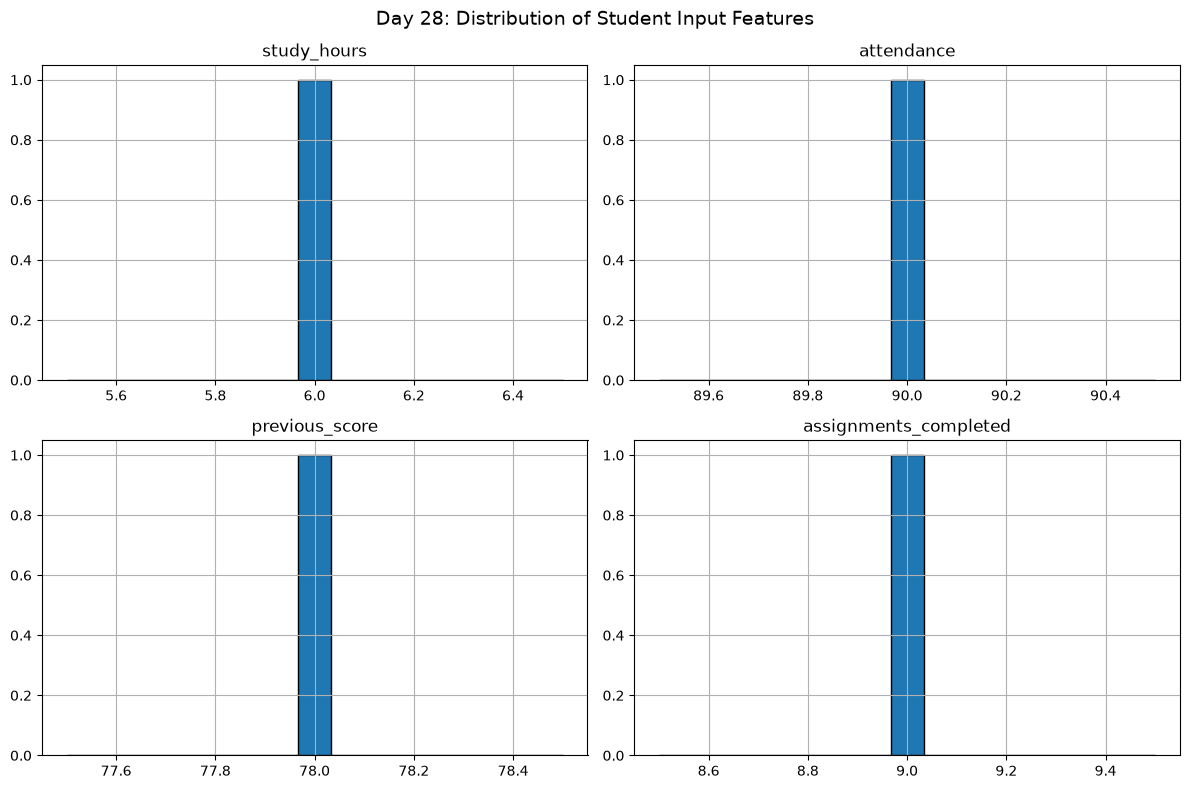

Feature distribution visualizations created successfully!


In [14]:
# Cell 7: Visualize Cleaned Input Features

if "X_clean" in globals() and not X_clean.empty:

    numeric_columns = X_clean.select_dtypes(
        include="number"
    ).columns.tolist()

    if numeric_columns:

        X_clean[numeric_columns].hist(
            figsize=(12, 8),
            bins=15,
            edgecolor="black"
        )

        plt.suptitle(
            "Day 28: Distribution of Student Input Features",
            fontsize=14
        )

        plt.tight_layout()
        plt.show()

        print("Feature distribution visualizations created successfully!")

    else:
        print("No numeric features available for visualization.")

else:
    print("Cleaned input features are not available. Please run Cell 6 first.")

Feature Correlation Matrix:


,study_hours,attendance,previous_score,assignments_completed
study_hours,NaN,NaN,NaN,NaN
attendance,NaN,NaN,NaN,NaN
previous_score,NaN,NaN,NaN,NaN
assignments_completed,NaN,NaN,NaN,NaN


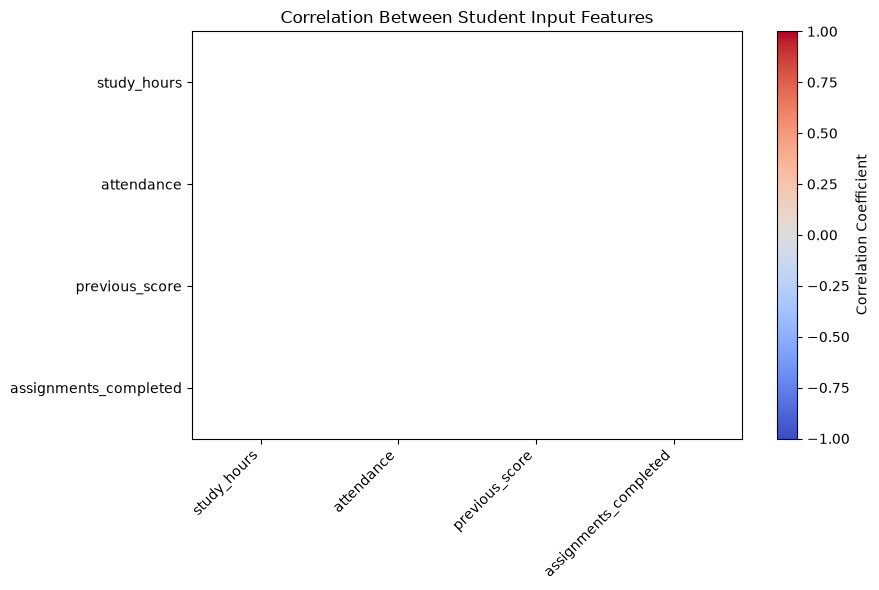

Feature correlation analysis completed!


In [15]:
# Cell 8: Feature Correlation Analysis

if "X_clean" in globals() and not X_clean.empty:

    numeric_features = X_clean.select_dtypes(
        include="number"
    )

    if numeric_features.shape[1] >= 2:

        feature_corr = numeric_features.corr()

        print("Feature Correlation Matrix:")
        display(feature_corr.round(2))

        plt.figure(figsize=(9, 6))

        plt.imshow(
            feature_corr,
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            aspect="auto"
        )

        plt.colorbar(label="Correlation Coefficient")

        plt.xticks(
            range(len(feature_corr.columns)),
            feature_corr.columns,
            rotation=45,
            ha="right"
        )

        plt.yticks(
            range(len(feature_corr.index)),
            feature_corr.index
        )

        plt.title("Correlation Between Student Input Features")

        for i in range(len(feature_corr.index)):
            for j in range(len(feature_corr.columns)):
                value = feature_corr.iloc[i, j]

                if pd.notna(value):
                    plt.text(
                        j, i, f"{value:.2f}",
                        ha="center",
                        va="center",
                        fontsize=9
                    )

        plt.tight_layout()
        plt.show()

        print("Feature correlation analysis completed!")

    else:
        print("At least two numeric features are required.")

else:
    print("Cleaned input features are not available. Please run Cell 6 first.")

Average Values of Student Input Features:


,Average
study_hours,6.0
attendance,90.0
previous_score,78.0
assignments_completed,9.0


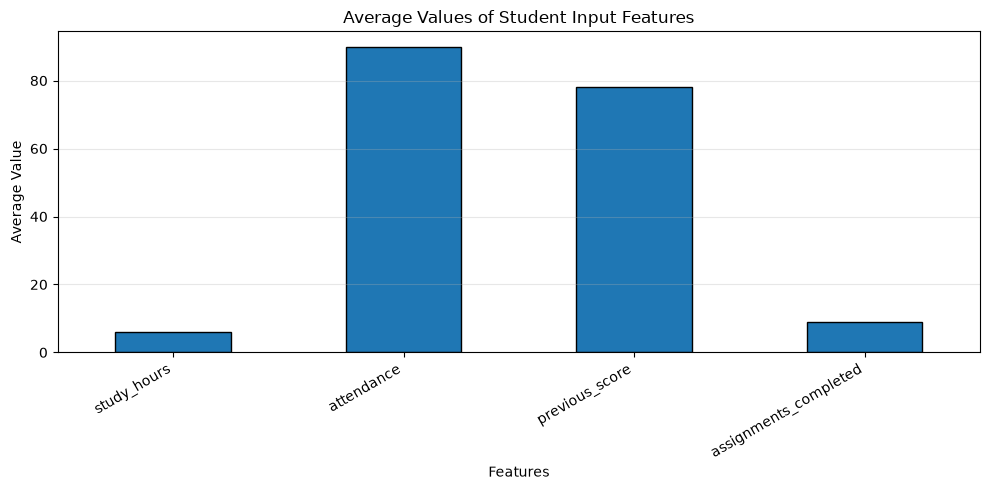

Feature average comparison completed!


In [17]:
# Cell 9: Compare Average Input Feature Values

if "X_clean" in globals() and not X_clean.empty:

    feature_averages = X_clean.mean(numeric_only=True)

    print("Average Values of Student Input Features:")
    display(feature_averages.to_frame("Average").round(2))

    if not feature_averages.empty:

        plt.figure(figsize=(10, 5))

        feature_averages.plot(kind="bar", edgecolor="black")

        plt.title("Average Values of Student Input Features")
        plt.xlabel("Features")
        plt.ylabel("Average Value")
        plt.xticks(rotation=30, ha="right")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

        print("Feature average comparison completed!")

    else:
        print("No numeric feature averages available.")

else:
    print("Cleaned input features are not available. Please run Cell 6 first.")

In [19]:
# Cell 10: Save Cleaned Student Features

if "X_clean" in globals() and not X_clean.empty:
    # Remove columns that contain only missing values
    X_final = X_clean.dropna(axis=1, how="all").copy()

    if not X_final.empty:
        output_path = Path.cwd() / "day28_cleaned_student_features.csv"

        X_final.to_csv(output_path, index=False)

        print("Cleaned student features saved successfully!")
        print("File path:", output_path.resolve())
        print("Number of rows:", X_final.shape[0])
        print("Number of features:", X_final.shape[1])
        display(X_final.head())
    else:
        print("No usable numeric features are available to save.")
else:
    print("X_clean is not available. Please run Cell 6 first.")

Cleaned student features saved successfully!
File path: C:\Internship_project\Data\day28_cleaned_student_features.csv
Number of rows: 1
Number of features: 4


,study_hours,attendance,previous_score,assignments_completed
0,6,90,78,9


In [21]:
# Cell 11: Final Dataset Summary

if "X_final" in globals() and not X_final.empty:
    print("=" * 50)
    print("DAY 28: STUDENT PERFORMANCE ANALYSIS SUMMARY")
    print("=" * 50)

    print("\n1. Dataset Overview")
    print("Total student records:", X_final.shape[0])
    print("Total input features:", X_final.shape[1])

    print("\n2. Input Feature Names")
    for feature in X_final.columns:
        print("-", feature)

    print("\n3. Missing Values")
    display(X_final.isnull().sum().to_frame("Missing Values"))

    print("\n4. Descriptive Statistics")
    display(X_final.describe().round(2))

    print("\n5. Final Status")
    print("Feature analysis completed.")
    print("Cleaned dataset is ready for further exploration.")
    print("Actual outcome labels are still needed for supervised model validation.")

else:
    print("X_final is not available. Please run Cell 10 first.")

DAY 28: STUDENT PERFORMANCE ANALYSIS SUMMARY

1. Dataset Overview
Total student records: 1
Total input features: 4

2. Input Feature Names
- study_hours
- attendance
- previous_score
- assignments_completed

3. Missing Values


,Missing Values
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



4. Descriptive Statistics


,study_hours,attendance,previous_score,assignments_completed
count,1.0,1.0,1.0,1.0
mean,6.0,90.0,78.0,9.0
std,NaN,NaN,NaN,NaN
min,6.0,90.0,78.0,9.0
25%,6.0,90.0,78.0,9.0
50%,6.0,90.0,78.0,9.0
75%,6.0,90.0,78.0,9.0
max,6.0,90.0,78.0,9.0



5. Final Status
Feature analysis completed.
Cleaned dataset is ready for further exploration.
Actual outcome labels are still needed for supervised model validation.


In [22]:
# Cell 12: Day 28 Completion Report

print("=" * 55)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 28 - COMPLETION REPORT")
print("=" * 55)

completed_tasks = [
    "Dataset loaded successfully",
    "Student input features selected",
    "Predicted performance column examined",
    "Input features converted to numeric format",
    "Missing values handled where possible",
    "Feature distributions visualized",
    "Feature correlations analyzed",
    "Feature averages compared",
    "Cleaned features saved to CSV",
    "Final dataset summary generated"
]

print("\nCompleted Tasks:\n")

for number, task in enumerate(completed_tasks, start=1):
    print(f"{number}. [DONE] {task}")

print("\nOutput File:")
print("day28_cleaned_student_features.csv")

print("\nImportant Note:")
print("Actual student performance labels are required")
print("to properly train and validate a supervised model.")

print("\nDay 28 analysis completed successfully!")
print("=" * 55)

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 28 - COMPLETION REPORT

Completed Tasks:

1. [DONE] Dataset loaded successfully
2. [DONE] Student input features selected
3. [DONE] Predicted performance column examined
4. [DONE] Input features converted to numeric format
5. [DONE] Missing values handled where possible
6. [DONE] Feature distributions visualized
7. [DONE] Feature correlations analyzed
8. [DONE] Feature averages compared
9. [DONE] Cleaned features saved to CSV
10. [DONE] Final dataset summary generated

Output File:
day28_cleaned_student_features.csv

Important Note:
Actual student performance labels are required
to properly train and validate a supervised model.

Day 28 analysis completed successfully!
